**Main imports**

In [1]:
# pip install numpy
# !pip install torch
# !pip install torchvision
# !pip install matplotlib

In [2]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from IPython import display as disp

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

**Import dataset**

In [3]:
# helper function to make getting another batch of data easier
def cycle(iterable):
    while True:
        for x in iterable:
            yield x

class_names = ['apple','aquarium_fish','baby','bear','beaver','bed','bee','beetle','bicycle','bottle','bowl','boy','bridge','bus','butterfly','camel','can','castle','caterpillar','cattle','chair','chimpanzee','clock','cloud','cockroach','couch','crab','crocodile','cup','dinosaur','dolphin','elephant','flatfish','forest','fox','girl','hamster','house','kangaroo','computer_keyboard','lamp','lawn_mower','leopard','lion','lizard','lobster','man','maple_tree','motorcycle','mountain','mouse','mushroom','oak_tree','orange','orchid','otter','palm_tree','pear','pickup_truck','pine_tree','plain','plate','poppy','porcupine','possum','rabbit','raccoon','ray','road','rocket','rose','sea','seal','shark','shrew','skunk','skyscraper','snail','snake','spider','squirrel','streetcar','sunflower','sweet_pepper','table','tank','telephone','television','tiger','tractor','train','trout','tulip','turtle','wardrobe','whale','willow_tree','wolf','woman','worm',]

train_loader = torch.utils.data.DataLoader(
    torchvision.datasets.CIFAR100('data', train=True, download=True, transform=torchvision.transforms.Compose([
        torchvision.transforms.ToTensor()
    ])),
    batch_size=64, drop_last=True)

test_loader = torch.utils.data.DataLoader(
    torchvision.datasets.CIFAR100('data', train=False, download=True, transform=torchvision.transforms.Compose([
        torchvision.transforms.ToTensor()
    ])),
    batch_size=64, drop_last=True)

train_iterator = iter(cycle(train_loader))
test_iterator = iter(cycle(test_loader))

print(f'> Size of training dataset {len(train_loader.dataset)}')
print(f'> Size of test dataset {len(test_loader.dataset)}')

/home3/hqcb32/deeplearningcourseworkenv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


> Size of training dataset 50000
> Size of test dataset 10000


**View some of the test dataset**

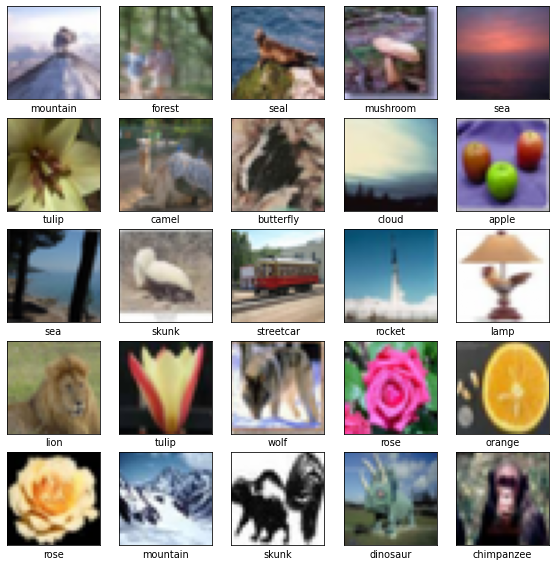

In [4]:
plt.rcParams['figure.dpi'] = 70
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    img = test_loader.dataset[i][0].numpy().transpose(1, 2, 0)
    plt.imshow(img)
    plt.xlabel(class_names[test_loader.dataset[i][1]])
plt.show()

**Define a simple model**

In [5]:
# Key ideas about the dataset we should keep in mind:
# 100 classes

# CIFAR-100 multiclass image classifier
# Input: 32x32 RGB images (B, 3, 32, 32)


class SE(nn.Module):
    def __init__(self, channels, reduction=32):
        super().__init__()
        hidden = max(1, channels // reduction)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Linear(channels, hidden, bias=True)
        self.fc2 = nn.Linear(hidden, channels, bias=True)

    def forward(self, x):
        b, c, _, _ = x.shape
        s = self.pool(x).view(b, c)          # (B, C)
        s = F.relu(self.fc1(s), inplace=True)
        s = torch.sigmoid(self.fc2(s)).view(b, c, 1, 1)  # (B, C, 1, 1)
        return x * s



# Output: 100-class logits (B, 100)
# Lightweight CNN using depthwise-separable convolutions to stay within the parameter budget.
class Classifier(nn.Module):
    def __init__(self, params, pdrop=0.1):
        #pdrop controls how much dropout regularization is applied
        super().__init__()

        # Stem: (B, 3, 32, 32) -> (B, 48, 32, 32)
        # Standard conv to go from raw RGB to learned feature maps
        # Conv2d(3→48, kernel=3×3): learns 48 filters that scan local 3×3 patches.
        # stride=1, padding=1: keeps spatial size 32×32.
        # bias=False: because BatchNorm has a learnable shift anyway; common and fine.
        # BatchNorm2d(48): stabilises training by normalising feature maps; also has learnable scale/shift.
        # Shape: (B, 3, 32, 32) → (B, 48, 32, 32)
        self.conv0 = nn.Conv2d(3, 48, 3, 1, 1, bias=False)
        self.bn0   = nn.BatchNorm2d(48)

        # These are Depth-Wise Seperable Convolutions
        # A “DS block” is:
        # 1. Depthwise conv: per-channel spatial filtering (cheap)
        # 2. Pointwise conv (1×1): mixes channels (cheap)
        # 3. BatchNorm + ReLU
        
        
        # DS1: 48 -> 48, stride 1  (32x32 stays)
        # groups=48 means each input channel gets its own 3×3 filter
        # So it learns 48 separate “edge/texture” filters, one per channel.
        
        # Then pw1 (1×1) mixes channels to combine those patterns.
        
        # Depthwise 3x3 (spatial filtering per-channel) + Pointwise 1x1 (channel mixing)
        
        # Shape stays: (B, 48, 32, 32) → (B, 48, 32, 32)        
        self.dw1 = nn.Conv2d(48, 48, 3, 1, 1, groups=48, bias=False)
        self.pw1 = nn.Conv2d(48, 48, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(48)

        # DS2: 48 -> 96, stride 2 so Downsample by splitting size in half (32x32 -> 16x16)
        # Downsample spatially and increase channels
        # This is the normal CNN pattern: spatial down, channels up, happy times
        # Shape: (B, 48, 32, 32) → (B, 96, 16, 16)        
        self.dw2 = nn.Conv2d(48, 48, 3, 2, 1, groups=48, bias=False)
        self.pw2 = nn.Conv2d(48, 96, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(96)

        # DS3: 96 -> 96, stride 1  (16x16 stays)
        # Shape: (B, 96, 16, 16) → (B, 96, 16, 16)        
        self.dw3 = nn.Conv2d(96, 96, 3, 1, 1, groups=96, bias=False)
        self.pw3 = nn.Conv2d(96, 96, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(96)

        # DS4: 96 -> 192, stride 2  (16x16 -> 8x8)
        # Shape: (B, 96, 16, 16) → (B, 192, 8, 8)       
        self.dw4 = nn.Conv2d(96, 96, 3, 2, 1, groups=96, bias=False)
        self.pw4 = nn.Conv2d(96, 192, 1, bias=False)
        self.bn4 = nn.BatchNorm2d(192)

        # DS5: 192 -> 192, stride 1  (8x8 stays)
        # Shape: (B, 192, 8, 8) → (B, 192, 8, 8)       
        self.dw5 = nn.Conv2d(192, 192, 3, 1, 1, groups=192, bias=False)
        self.pw5 = nn.Conv2d(192, 192, 1, bias=False)
        self.bn5 = nn.BatchNorm2d(192)
        self.se5 = SE(192, reduction=48)
        
        # Head: Global average pooling + linear classifier
        # AdaptiveAvgPool2d(1) averages each feature map into a single number:
        # (B, 192, 8, 8) -> (B, 192) -> (B, 100)
        
        # .flatten(1) turns that into (B, 192)
        # Dropout randomly zeros some activations during training → helps generalisation
        # Linear maps 192 features → 100 logits
        # Final output: (B, 100) logits (not probabilities)       
        self.drop = nn.Dropout(pdrop)
        self.pool = nn.AdaptiveAvgPool2d(1)   # (B, 96, 8, 8) -> (B, 96, 1, 1)
        self.fc  = nn.Linear(192, params["n_classes"])

    def forward(self, x):
        # Stem
        # conv extracts features
        # BN stabilises them
        # ReLU adds non-linearity
        x = F.relu(self.bn0(self.conv0(x)), inplace=True)

        # DS1
        identity = x
        x = self.dw1(x)
        x = self.pw1(x)
        x = x + identity
        x = F.relu(self.bn1(x), inplace=True)
        
        # DS2 (downsample)
        x = self.dw2(x)
        x = self.pw2(x)
        x = F.relu(self.bn2(x), inplace=True)

        # DS3
        identity = x
        x = self.dw3(x)
        x = self.pw3(x)
        x = x + identity
        x = F.relu(self.bn3(x), inplace=True)

        # DS4 (downsample)
        x = self.dw4(x)
        x = self.pw4(x)
        x = F.relu(self.bn4(x), inplace=True)

        # DS5
        identity = x
        x = self.dw5(x)
        x = self.pw5(x)
        x = x + identity
        x = F.relu(self.bn5(x), inplace=True)
        x = self.se5(x)

        # Head
        x = self.pool(x).flatten(1)
        x = self.drop(x)
        x = self.fc(x)
        return x
    

    
    
    

# hyperparameters
params = {
    'n_channels': 3,  # number of channels
    'n_hidden':   30, # change to increase parameters
    'n_classes':  100 # number of classes for CIFAR-100
}




N = Classifier(params).to(device)




# print the number of parameters - this should be included in your report
print(f'> Number of parameters {len(torch.nn.utils.parameters_to_vector(N.parameters()))}')

n_params = sum(p.numel() for p in N.parameters())
print(n_params)

if len(torch.nn.utils.parameters_to_vector(N.parameters())) > 100000:
    print("> Warning: you have gone over your parameter budget and will have a grade penalty!")


# creating variables for optimisation and warmup
base_lr = 0.007
warmup_steps = 1000
total_steps = 10000


# initialise the optimiser
# AdamW updates weights quickly in few steps. weight_decay discourages overly large weights → generalisation.
optimiser = torch.optim.AdamW(N.parameters(), lr=base_lr, weight_decay = 0.001)

# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=10000, eta_min=1e-5)

# trying to do a warmup
def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / (total_steps - warmup_steps)
    return 0.5 * (1 + np.cos(np.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimiser, lr_lambda)



plot_data = []
steps = 0

> Number of parameters 99416
99416


In [7]:
print(f'> Number of parameters {len(torch.nn.utils.parameters_to_vector(N.parameters()))}')

> Number of parameters 99416


**Main training and testing loop**

steps: 10000.00, train loss: 1.867, train acc: 0.690±0.060, test acc: 0.577±0.063


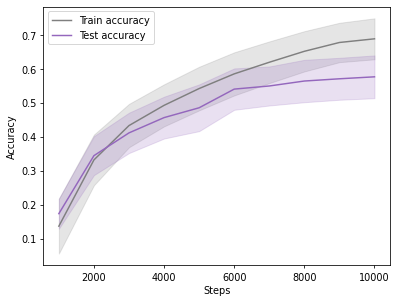

In [8]:
# Loss Function
# Label smoothing prevents the model becoming overconfident; usually helps CIFAR-100.
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

# keep within our optimisation step budget
while (steps < 10000):

    # arrays for metrics
    train_loss_arr = np.zeros(0)
    train_acc_arr = np.zeros(0)
    test_acc_arr = np.zeros(0)

    # iterate through some of the TRAIN dateset
    for i in range(1000):
        x,t = next(train_iterator)
        x,t = x.to(device), t.to(device)

        optimiser.zero_grad()
        p = N(x)
        pred = p.argmax(dim=1, keepdim=True)
        # loss = torch.nn.functional.cross_entropy(p, t)
        loss = criterion(p, t)
        loss.backward()
        optimiser.step()
        # scheduler step
        scheduler.step()
        steps += 1

        train_loss_arr = np.append(train_loss_arr, loss.cpu().data)
        train_acc_arr = np.append(train_acc_arr, pred.data.eq(t.view_as(pred)).float().mean().item())
    
    # Switching to the test mode since we hace now done this training
    N.eval()  # switch to evaluation mode (Dropout OFF, BatchNorm fixed)
    
    # iterate over the entire TEST dataset
    with torch.no_grad():  # no gradient tracking
        for x,t in test_loader:
            x,t = x.to(device), t.to(device)
            p = N(x)
            # loss = torch.nn.functional.cross_entropy(p, t)
            loss = criterion(p, t)
            pred = p.argmax(dim=1, keepdim=True)
            test_acc_arr = np.append(test_acc_arr, pred.data.eq(t.view_as(pred)).float().mean().item())
    
    # printing your loss and accuracy data
    print('steps: {:.2f}, train loss: {:.3f}, train acc: {:.3f}±{:.3f}, test acc: {:.3f}±{:.3f}'.format(
        steps, train_loss_arr.mean(),train_acc_arr.mean(),train_acc_arr.std(),test_acc_arr.mean(),test_acc_arr.std()))
    
    # switching back to training mode
    N.train() 
    
    # plot your accuracy graph - add a graph like this in your final report
    plot_data.append([steps, np.array(train_acc_arr).mean(), np.array(train_acc_arr).std(), np.array(test_acc_arr).mean(), np.array(test_acc_arr).std()])
    reward_list = []
    plt.plot([x[0] for x in plot_data], [x[1] for x in plot_data], '-', color='tab:grey', label="Train accuracy")
    plt.fill_between([x[0] for x in plot_data], [x[1]-x[2] for x in plot_data], [x[1]+x[2] for x in plot_data], alpha=0.2, color='tab:grey')
    plt.plot([x[0] for x in plot_data], [x[3] for x in plot_data], '-', color='tab:purple', label="Test accuracy")
    plt.fill_between([x[0] for x in plot_data], [x[3]-x[4] for x in plot_data], [x[3]+x[4] for x in plot_data], alpha=0.2, color='tab:purple')
    plt.xlabel('Steps')
    plt.ylabel('Accuracy')
    plt.legend(loc="upper left")
    plt.show()
    disp.clear_output(wait=True)

**Inference on dataset**

This is useful for analysis but is entirely optional

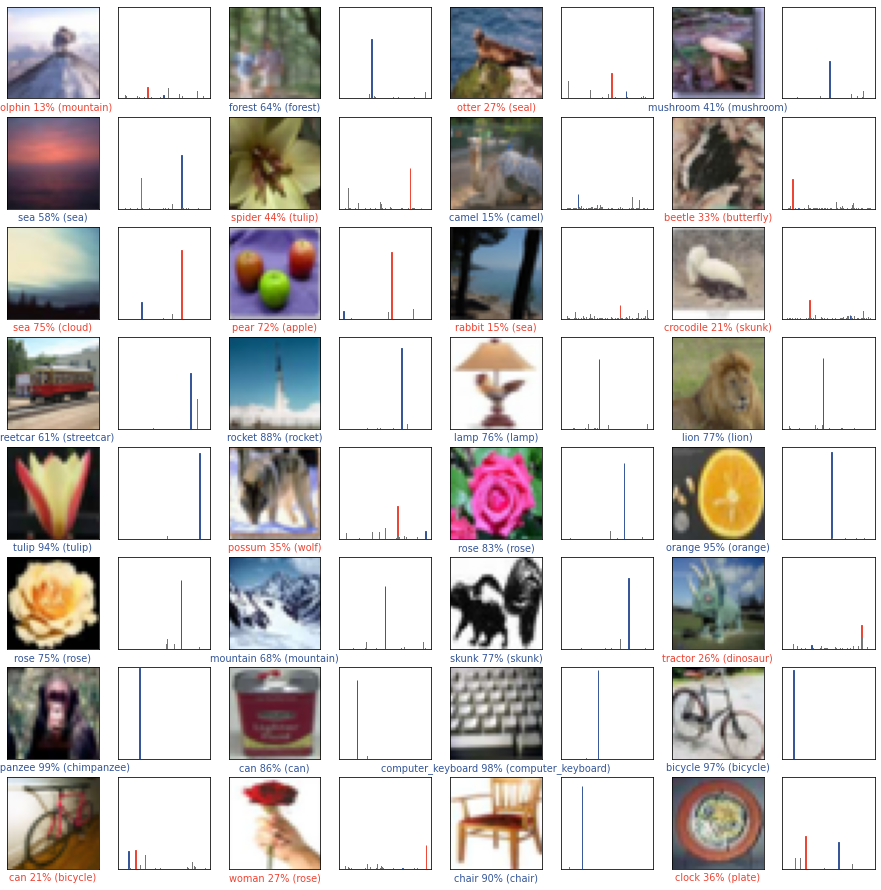

In [15]:
def plot_image(i, predictions_array, true_label, img):
    predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    img = np.transpose(img, (1, 2, 0))
    plt.imshow(img)

    predicted_label = np.argmax(predictions_array)
    color = '#335599' if predicted_label == true_label else '#ee4433'

    plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                  100*np.max(predictions_array),
                                  class_names[true_label]),
                                  color=color)

def plot_value_array(i, predictions_array, true_label):
    predictions_array, true_label = predictions_array[i], true_label[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    thisplot = plt.bar(range(100), predictions_array, color="#777777")
    plt.ylim([0, 1])
    predicted_label = np.argmax(predictions_array)

    thisplot[predicted_label].set_color('#ee4433')
    thisplot[true_label].set_color('#335599')

test_images, test_labels = next(test_iterator)
test_images, test_labels = test_images.to(device), test_labels.to(device)
test_preds = torch.softmax(N(test_images), dim=1).data.cpu().numpy()
num_rows = 8
num_cols = 4
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
    plt.subplot(num_rows, 2*num_cols, 2*i+1)
    plot_image(i, test_preds, test_labels.cpu().numpy(), test_images.cpu().numpy()) # Used .numpy() here
    plt.subplot(num_rows, 2*num_cols, 2*i+2)
    plot_value_array(i, test_preds, test_labels.cpu().numpy())

In [ ]:
# The hyperparameter optimisation code was ran on a separate .ipynb file
# That was for the sake of me not making this code extremely messy and having to repeat things.